# Zebrahub extra data → training crops

Turns the raw embryo downloaded from the public [zebrahub imaging
release](https://public.czbiohub.org/royerlab/zebrahub/imaging/single-objective/)
(`ZSNS001_tail`, full resolution, see `scripts/download_zebrahub.py`) into a
handful of crops in the same format the synthetic generator writes
(`input/synthetic/v*/sequences/seq_*.npz`), so they can eventually be mixed
into training the same way.

Two real discrepancies to correct for, on top of cropping (see the two
sections below for details):

- **Resolution**: the raw zarr is `(1.24, 0.439, 0.439)` µm/voxel; the
  competition data is `(1.625, 0.40625, 0.40625)` µm/voxel (`params.SCALE`).
  Resampled with the same trilinear method `tracking_cellmot.io._process_on_gpu`
  uses for `target_scale`.
- **Track coordinates**: `*_tracks.csv` stores `z, y, x` in **physical
  micrometers**, not voxel indices like the competition `.geff` files. Divide
  by the target voxel scale to land in the same pixel-index space.

Raw intensity range is *not* corrected here — the raw crop tops out around
150-300 vs. ~4000+ for the competition data, but every loader in this repo
(`tracking.data.normalize_frames`, `tracking.synthetic.SyntheticDataset`)
already re-normalises per-video/per-sequence against its own quantiles, so
storing raw counts and normalising at load time is the existing convention,
not a gap to paper over. The plots at the end check that this actually washes
the mismatch out.


In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
cd ../src

/data/kaggle_biohub_cell_tracking/src


In [3]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import polars as pl
import torch
import torch.nn.functional as F
import zarr

from params import SCALE as TARGET_SCALE
from utils.plot import scatter_by_depth


## Configuration

`EMBRYO_DIR` is where `scripts/download_zebrahub.py --embryo ZSNS001_tail`
put things. `CROP_SHAPE` matches the competition crops' `(Z, Y, X)` — 64
z-slices, 256×256 in-plane — so a `(2, 64, 256, 256)` window is exactly what
one `TrackDataset`/`SyntheticDataset` window looks like at `window_size=2`.


In [4]:
EMBRYO_DIR = Path("../zebrahub_raw/ZSNS001_tail")
ZARR_PATH = EMBRYO_DIR / "ZSNS001_tail.ome.zarr"
CSV_PATH = EMBRYO_DIR / "ZSNS001_tail_tracks.csv"

CROP_SHAPE = (64, 256, 256)   # (Z, Y, X), voxels, at TARGET_SCALE
WINDOW_SIZE = 2               # frames per crop — matches load_dataset_windows' default
N_DENSE_CROPS = 3             # cell-dense crops, for a general look
N_DIVISION_CROPS = 1          # crop centred on a division event

OUT_DIR = Path("../input/zebrahub_crops/v1")
(OUT_DIR / "sequences").mkdir(parents=True, exist_ok=True)

SEED = 0
rng = np.random.default_rng(SEED)


## Load the source data

The zarr's own `.zattrs` carries its native voxel scale (OME-NGFF
`coordinateTransformations`); `params.SCALE` is the competition's. `ParentTrackID`
turns out to be constant per track and, whenever set, names a track with
*exactly* two children — i.e. it only ever marks a division, never plain track
fragmentation — so it doubles as a clean division flag once grouped by
`track_id`.


In [5]:
g = zarr.open_group(ZARR_PATH, mode="r")
attrs = g.attrs.asdict()
NATIVE_SCALE = tuple(attrs["multiscales"][0]["datasets"][0]["coordinateTransformations"][0]["scale"][-3:])
arr = g["0"]  # (T, C, Z, Y, X) uint16

print(f"native scale (z,y,x) : {NATIVE_SCALE} um/voxel")
print(f"target scale (z,y,x) : {tuple(TARGET_SCALE)} um/voxel")
print(f"zoom factor           : {[round(n / t, 3) for n, t in zip(NATIVE_SCALE, TARGET_SCALE)]}")
print(f"image shape (T,C,Z,Y,X): {arr.shape}")

VOLUME_EXTENT_UM = tuple(s * sc for s, sc in zip(arr.shape[2:], NATIVE_SCALE))
print(f"volume extent (z,y,x) um: {VOLUME_EXTENT_UM}")


native scale (z,y,x) : (1.24, 0.439, 0.439) um/voxel
target scale (z,y,x) : (1.625, 0.40625, 0.40625) um/voxel
zoom factor           : [0.763, 1.081, 1.081]
image shape (T,C,Z,Y,X): (791, 1, 420, 1217, 1091)
volume extent (z,y,x) um: (520.8, 534.263, 478.949)


In [6]:
tracks = pl.read_csv(CSV_PATH).with_columns(
    pl.col("ParentTrackID").cast(pl.Float64, strict=False).cast(pl.Int64, strict=False)
)
parent_map = tracks.group_by("track_id").agg(pl.col("ParentTrackID").first().alias("parent_track_id"))

n_divisions = parent_map["parent_track_id"].drop_nulls().n_unique()
print(f"{tracks.height:,} track rows, {tracks['track_id'].n_unique():,} tracks, {n_divisions:,} division events")
tracks.head()


7,505,357 track rows, 101,676 tracks, 36,878 division events


track_id,NodeID,ParentTrackID,t,t_hier_id,z,y,x,area
i64,i64,i64,f64,f64,f64,f64,f64,f64
1,10000001,null,0.0,1.0,440.2,111.945,184.819,3067.0
1,20000015,null,1.0,2.0,441.44,111.945,184.819,3296.0
1,30000054,null,2.0,5.0,438.96,111.506,183.941,3234.0
1,40001034,null,3.0,72.0,438.96,111.945,185.697,3125.0
1,50004685,null,4.0,151.0,438.96,111.506,185.258,3422.0


## Resolution & intensity distribution vs. the competition data

Confirms the two numbers from the intro against one real competition sample:
the voxel scale really does differ, and the raw dynamic range really is much
smaller here — but normalising each volume against its own low/high quantile
(exactly what `tracking.data.normalize_frames` / `SyntheticDataset._one` do at
load time) brings the two into the same range regardless.


In [7]:
COMPETITION_SAMPLE = Path("../input/train/44b6_0113de3b.zarr")
comp = zarr.open_group(COMPETITION_SAMPLE, mode="r")
comp_attrs = comp.attrs.asdict()
comp_scale = tuple(comp_attrs["multiscales"][0]["datasets"][0]["coordinateTransformations"][0]["scale"][-3:])
comp_q = comp_attrs["image_statistics"]["quantiles"]
comp_frame = np.asarray(comp["0"][0])  # (Z, Y, X)

raw_frame = np.asarray(arr[0, 0])  # native-resolution t=0 frame of the whole embryo, for reference only
print(f"competition sample voxel scale: {comp_scale} um  (TARGET_SCALE: {tuple(TARGET_SCALE)})")
print(f"competition frame value range : {comp_frame.min()}-{comp_frame.max()}, "
      f"q0.999={comp_q['0.999']:.0f}")
print(f"zebrahub frame value range    : {raw_frame.min()}-{raw_frame.max()}, "
      f"q0.999={np.quantile(raw_frame[raw_frame > 0], 0.999):.1f} (nonzero voxels)")


competition sample voxel scale: (1.625, 0.40625, 0.40625) um  (TARGET_SCALE: (1.625, 0.40625, 0.40625))
competition frame value range : 12-2950, q0.999=2145
zebrahub frame value range    : 0-271, q0.999=164.0 (nonzero voxels)


## Picking crop locations

A `104x104x104` µm cube (`CROP_SHAPE * TARGET_SCALE`) is dense-cell-search
sized on a coarse grid at `t=0`, taking the top-3 non-overlapping cells; a
fourth crop is centred on a random division event's parent-node position so
at least one crop actually exercises the division supervision path.


In [8]:
def find_dense_crop_origins(nodes_t, crop_um, n=3, step_um=20.0):
    """Grid-search axis-aligned crop_um-sized boxes with the most nodes_t rows inside."""
    z, y, x = (nodes_t[c].to_numpy() for c in ("z", "y", "x"))
    cands = []
    for z0 in np.arange(z.min(), z.max() - crop_um[0], step_um):
        for y0 in np.arange(y.min(), y.max() - crop_um[1], step_um):
            for x0 in np.arange(x.min(), x.max() - crop_um[2], step_um):
                m = (
                    (z >= z0) & (z < z0 + crop_um[0])
                    & (y >= y0) & (y < y0 + crop_um[1])
                    & (x >= x0) & (x < x0 + crop_um[2])
                )
                cands.append((int(m.sum()), float(z0), float(y0), float(x0)))
    cands.sort(key=lambda c: -c[0])

    picked = []
    for n_hits, z0, y0, x0 in cands:
        if all(
            abs(pz - z0) >= crop_um[0] or abs(py - y0) >= crop_um[1] or abs(px - x0) >= crop_um[2]
            for _, pz, py, px in picked
        ):
            picked.append((n_hits, z0, y0, x0))
        if len(picked) == n:
            break
    return picked


CROP_UM = tuple(s * sc for s, sc in zip(CROP_SHAPE, TARGET_SCALE))
print(f"crop physical size (z,y,x): {CROP_UM} um")

t0_nodes = tracks.filter(pl.col("t") == 0)
dense = find_dense_crop_origins(t0_nodes, CROP_UM, n=N_DENSE_CROPS)
for n_hits, z0, y0, x0 in dense:
    print(f"  dense crop: {n_hits} cells at t=0, origin (z,y,x)=({z0:.1f}, {y0:.1f}, {x0:.1f})")


crop physical size (z,y,x): (104.0, 104.0, 104.0) um
  dense crop: 484 cells at t=0, origin (z,y,x)=(320.9, 65.4, 141.8)
  dense crop: 387 cells at t=0, origin (z,y,x)=(260.9, 185.4, 101.8)
  dense crop: 146 cells at t=0, origin (z,y,x)=(380.9, 185.4, 61.8)


In [9]:
def clip_origin(origin_um, crop_um, extent_um):
    return tuple(
        float(np.clip(o, 0.0, e - c)) for o, c, e in zip(origin_um, crop_um, extent_um)
    )


division_parents = parent_map["parent_track_id"].drop_nulls().unique().to_list()
chosen_parent = int(rng.choice(division_parents))
parent_last = (
    tracks.filter(pl.col("track_id") == chosen_parent).sort("t").tail(1)
)
div_t0 = int(parent_last["t"].item())
div_center = (parent_last["z"].item(), parent_last["y"].item(), parent_last["x"].item())
div_origin = clip_origin(
    tuple(c - u / 2 for c, u in zip(div_center, CROP_UM)), CROP_UM, VOLUME_EXTENT_UM
)
print(f"division crop: parent track {chosen_parent}, t0={div_t0}, origin (z,y,x)={div_origin}")

CROP_SPECS = [
    {"name": f"dense_{i}", "origin_um": (z0, y0, x0), "t0": 0}
    for i, (_, z0, y0, x0) in enumerate(dense)
] + [
    {"name": "division_0", "origin_um": div_origin, "t0": div_t0},
]
CROP_SPECS


division crop: parent track 76135, t0=635, origin (z,y,x)=(125.32, 254.861, 337.832)


[{'name': 'dense_0', 'origin_um': (320.88, 65.411, 141.756), 't0': 0},
 {'name': 'dense_1', 'origin_um': (260.88, 185.411, 101.756), 't0': 0},
 {'name': 'dense_2', 'origin_um': (380.88, 185.411, 61.756), 't0': 0},
 {'name': 'division_0', 'origin_um': (125.32, 254.861, 337.832), 't0': 635}]

## Extraction: image resample + node/edge/division tables

`build_crop` does the two conversions from the intro and nothing else:

- reads the native-resolution voxel box that covers the crop, then
  `interpolate(..., mode="trilinear")`s it to `CROP_SHAPE` — the same call
  `tracking_cellmot.io._process_on_gpu` makes for `target_scale`;
- takes every track row inside the crop's space-time box, converts its
  micrometer `z, y, x` straight to local target-grid pixels
  (`(um - origin_um) / TARGET_SCALE`, no intermediate native-pixel step needed
  since the CSV is already physical units), and links consecutive-frame rows
  of the same `track_id` (continuation) or a parent's last row to its two
  children's first rows (division, via `parent_track_id`).

Output arrays match `tracking.synthetic` exactly: `volumes (T,Z,Y,X) uint16`
raw, `nodes (N,5) float32 [t,z,y,x,track_id]`, `edges (E,2) int32` row-index
pairs into `nodes`, `divisions (D,) int32` row indices with two children.


In [10]:
def native_px_box(origin_um, crop_um, native_scale, volume_shape):
    starts = [int(round(o / ns)) for o, ns in zip(origin_um, native_scale)]
    stops = [int(round((o + c) / ns)) for o, c, ns in zip(origin_um, crop_um, native_scale)]
    # Guard the volume edge: a crop near the boundary can round past it by a voxel.
    starts = [max(0, s) for s in starts]
    stops = [min(v, e) for v, e in zip(volume_shape, stops)]
    return tuple(starts), tuple(stops)


def extract_and_resample(t0, starts, stops, shape_px):
    raw = arr[t0 : t0 + WINDOW_SIZE, 0, starts[0]:stops[0], starts[1]:stops[1], starts[2]:stops[2]]
    raw = torch.from_numpy(np.asarray(raw, dtype=np.float32))[:, None]  # (W,1,Z,Y,X)
    out = F.interpolate(raw, size=shape_px, mode="trilinear", align_corners=False)[:, 0]
    return out.round().clamp(0, 65535).to(torch.uint16).numpy()


def build_nodes_edges(origin_um, crop_um, t0):
    z0, y0, x0 = origin_um
    sub = tracks.filter(
        (pl.col("t") >= t0) & (pl.col("t") < t0 + WINDOW_SIZE)
        & (pl.col("z") >= z0) & (pl.col("z") < z0 + crop_um[0])
        & (pl.col("y") >= y0) & (pl.col("y") < y0 + crop_um[1])
        & (pl.col("x") >= x0) & (pl.col("x") < x0 + crop_um[2])
    ).join(parent_map, on="track_id", how="left")

    frames = [sub.filter(pl.col("t") == t0 + w) for w in range(WINDOW_SIZE)]
    rows = pl.concat([f.with_columns(pl.lit(w).alias("w")) for w, f in enumerate(frames)])
    node_row = {nid: i for i, nid in enumerate(rows["NodeID"].to_list())}

    nodes = np.zeros((rows.height, 5), dtype=np.float32)
    nodes[:, 0] = rows["w"].to_numpy()
    nodes[:, 1] = (rows["z"].to_numpy() - z0) / TARGET_SCALE[0]
    nodes[:, 2] = (rows["y"].to_numpy() - y0) / TARGET_SCALE[1]
    nodes[:, 3] = (rows["x"].to_numpy() - x0) / TARGET_SCALE[2]
    nodes[:, 4] = rows["track_id"].to_numpy()

    edge_pairs = []
    for w in range(WINDOW_SIZE - 1):
        cont = frames[w].join(frames[w + 1], on="track_id", suffix="_c")
        edge_pairs += list(zip(cont["NodeID"].to_list(), cont["NodeID_c"].to_list()))
        div = frames[w].join(frames[w + 1], left_on="track_id", right_on="parent_track_id", suffix="_c")
        edge_pairs += list(zip(div["NodeID"].to_list(), div["NodeID_c"].to_list()))

    edges = np.array([[node_row[a], node_row[b]] for a, b in edge_pairs], dtype=np.int32)
    edges = edges.reshape(-1, 2)

    out_deg = np.bincount(edges[:, 0], minlength=rows.height) if edges.size else np.zeros(rows.height)
    divisions = np.nonzero(out_deg == 2)[0].astype(np.int32)

    return nodes, edges, divisions


def build_crop(spec):
    origin_um, t0 = spec["origin_um"], spec["t0"]
    starts, stops = native_px_box(origin_um, CROP_UM, NATIVE_SCALE, arr.shape[2:])
    volumes = extract_and_resample(t0, starts, stops, CROP_SHAPE)
    nodes, edges, divisions = build_nodes_edges(origin_um, CROP_UM, t0)

    out = {
        "volumes": volumes,
        "nodes": nodes,
        "edges": edges,
        "divisions": divisions,
        "voxel_um": np.array(TARGET_SCALE, dtype=np.float32),
    }
    path = OUT_DIR / "sequences" / f"seq_{spec['name']}.npz"
    np.savez(path, **out)
    return out, path


In [11]:
manifest = []
built = {}
for spec in CROP_SPECS:
    out, path = build_crop(spec)
    n_nodes_per_frame = [int((out["nodes"][:, 0] == w).sum()) for w in range(WINDOW_SIZE)]
    entry = {
        "name": spec["name"],
        "path": str(path.relative_to(OUT_DIR.parent.parent)),
        "t0": spec["t0"],
        "origin_um": spec["origin_um"],
        "shape": list(out["volumes"].shape),
        "n_nodes_per_frame": n_nodes_per_frame,
        "n_edges": int(out["edges"].shape[0]),
        "n_divisions": int(out["divisions"].shape[0]),
    }
    manifest.append(entry)
    built[spec["name"]] = out
    print(f"{spec['name']:>12}: nodes/frame={n_nodes_per_frame} edges={entry['n_edges']} "
          f"divisions={entry['n_divisions']} -> {path.name}")

metadata = {
    "source": "public.czbiohub.org zebrahub ZSNS001_tail, level 0",
    "voxel_um": list(TARGET_SCALE),
    "crop_shape": list(CROP_SHAPE),
    "window_size": WINDOW_SIZE,
    "seed": SEED,
    "n_sequences": len(manifest),
    "sequences": manifest,
}
with open(OUT_DIR / "metadata.json", "w") as f:
    json.dump(metadata, f, indent=2)
metadata


     dense_0: nodes/frame=[484, 482] edges=479 divisions=0 -> seq_dense_0.npz


     dense_1: nodes/frame=[387, 386] edges=379 divisions=0 -> seq_dense_1.npz
     dense_2: nodes/frame=[146, 146] edges=146 divisions=0 -> seq_dense_2.npz
  division_0: nodes/frame=[963, 965] edges=945 divisions=5 -> seq_division_0.npz


{'source': 'public.czbiohub.org zebrahub ZSNS001_tail, level 0',
 'voxel_um': [1.625, 0.40625, 0.40625],
 'crop_shape': [64, 256, 256],
 'window_size': 2,
 'seed': 0,
 'n_sequences': 4,
 'sequences': [{'name': 'dense_0',
   'path': 'zebrahub_crops/v1/sequences/seq_dense_0.npz',
   't0': 0,
   'origin_um': (320.88, 65.411, 141.756),
   'shape': [2, 64, 256, 256],
   'n_nodes_per_frame': [484, 482],
   'n_edges': 479,
   'n_divisions': 0},
  {'name': 'dense_1',
   'path': 'zebrahub_crops/v1/sequences/seq_dense_1.npz',
   't0': 0,
   'origin_um': (260.88, 185.411, 101.756),
   'shape': [2, 64, 256, 256],
   'n_nodes_per_frame': [387, 386],
   'n_edges': 379,
   'n_divisions': 0},
  {'name': 'dense_2',
   'path': 'zebrahub_crops/v1/sequences/seq_dense_2.npz',
   't0': 0,
   'origin_um': (380.88, 185.411, 61.756),
   'shape': [2, 64, 256, 256],
   'n_nodes_per_frame': [146, 146],
   'n_edges': 146,
   'n_divisions': 0},
  {'name': 'division_0',
   'path': 'zebrahub_crops/v1/sequences/seq_di

## Visual checks

### Intensity distribution, before and after per-volume normalisation

Same normalisation every loader in this repo applies
(`low_q=0.001, high_q=0.999, clamp_max=4.0` — `tracking.data.NORM_DEFAULTS`),
computed from each volume's own quantiles (competition: stored in zarr attrs;
zebrahub crop: computed on the fly, exactly like `SyntheticDataset._one`
does for the synthetic set, since nothing is precomputed for it). Raw ranges
start far apart; normalised, cell-vs-background contrast lines up.


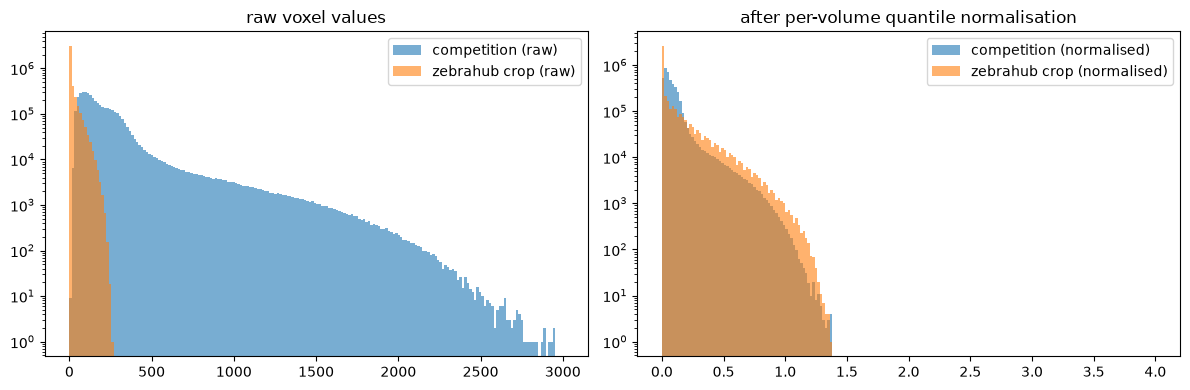

In [12]:
def normalize(x, lo, hi, clamp=4.0):
    return np.clip((x.astype(np.float32) - lo) / (hi - lo + 1e-6), 0.0, clamp)


crop_frame = built["dense_0"]["volumes"][0].astype(np.float32)
crop_lo, crop_hi = np.quantile(crop_frame, [0.001, 0.999])
comp_lo, comp_hi = comp_q["0.001"], comp_q["0.999"]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(comp_frame.ravel(), bins=200, range=(0, 3000), alpha=0.6, label="competition (raw)", color="tab:blue")
axes[0].hist(crop_frame.ravel(), bins=200, range=(0, 3000), alpha=0.6, label="zebrahub crop (raw)", color="tab:orange")
axes[0].set_yscale("log")
axes[0].set_title("raw voxel values")
axes[0].legend()

axes[1].hist(normalize(comp_frame, comp_lo, comp_hi).ravel(), bins=200, range=(0, 4), alpha=0.6,
             label="competition (normalised)", color="tab:blue")
axes[1].hist(normalize(crop_frame, crop_lo, crop_hi).ravel(), bins=200, range=(0, 4), alpha=0.6,
             label="zebrahub crop (normalised)", color="tab:orange")
axes[1].set_yscale("log")
axes[1].set_title("after per-volume quantile normalisation")
axes[1].legend()
plt.tight_layout()
plt.show()


### Cells over the image, per crop

One row per crop, one column per frame of the window — the resampled image at
the z-plane with the most annotated cells, cell centres drawn with
`scatter_by_depth` (fading with distance from that plane, same as everywhere
else in this repo).


In [13]:
CROP_SPECS

[{'name': 'dense_0', 'origin_um': (320.88, 65.411, 141.756), 't0': 0},
 {'name': 'dense_1', 'origin_um': (260.88, 185.411, 101.756), 't0': 0},
 {'name': 'dense_2', 'origin_um': (380.88, 185.411, 61.756), 't0': 0},
 {'name': 'division_0', 'origin_um': (125.32, 254.861, 337.832), 't0': 635}]

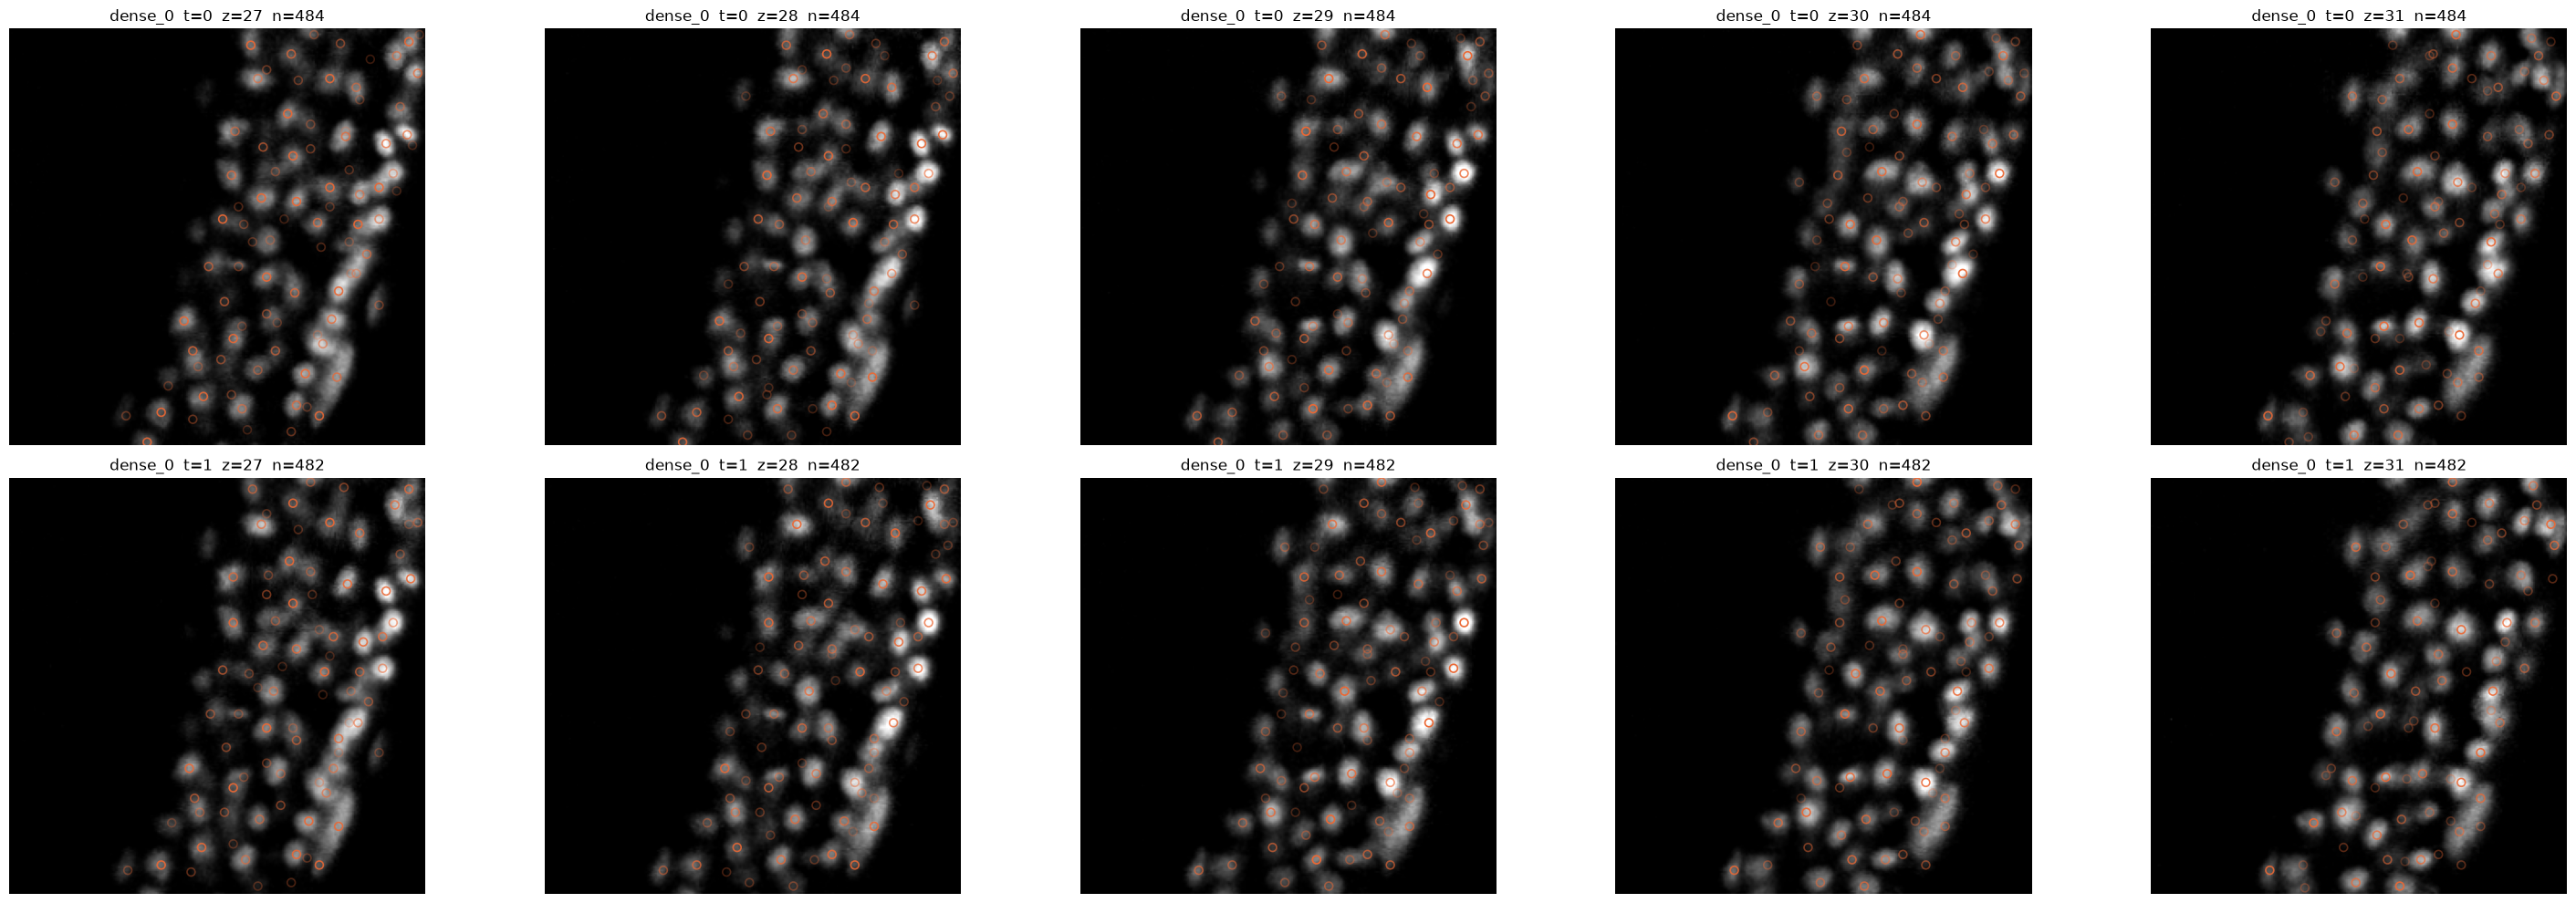

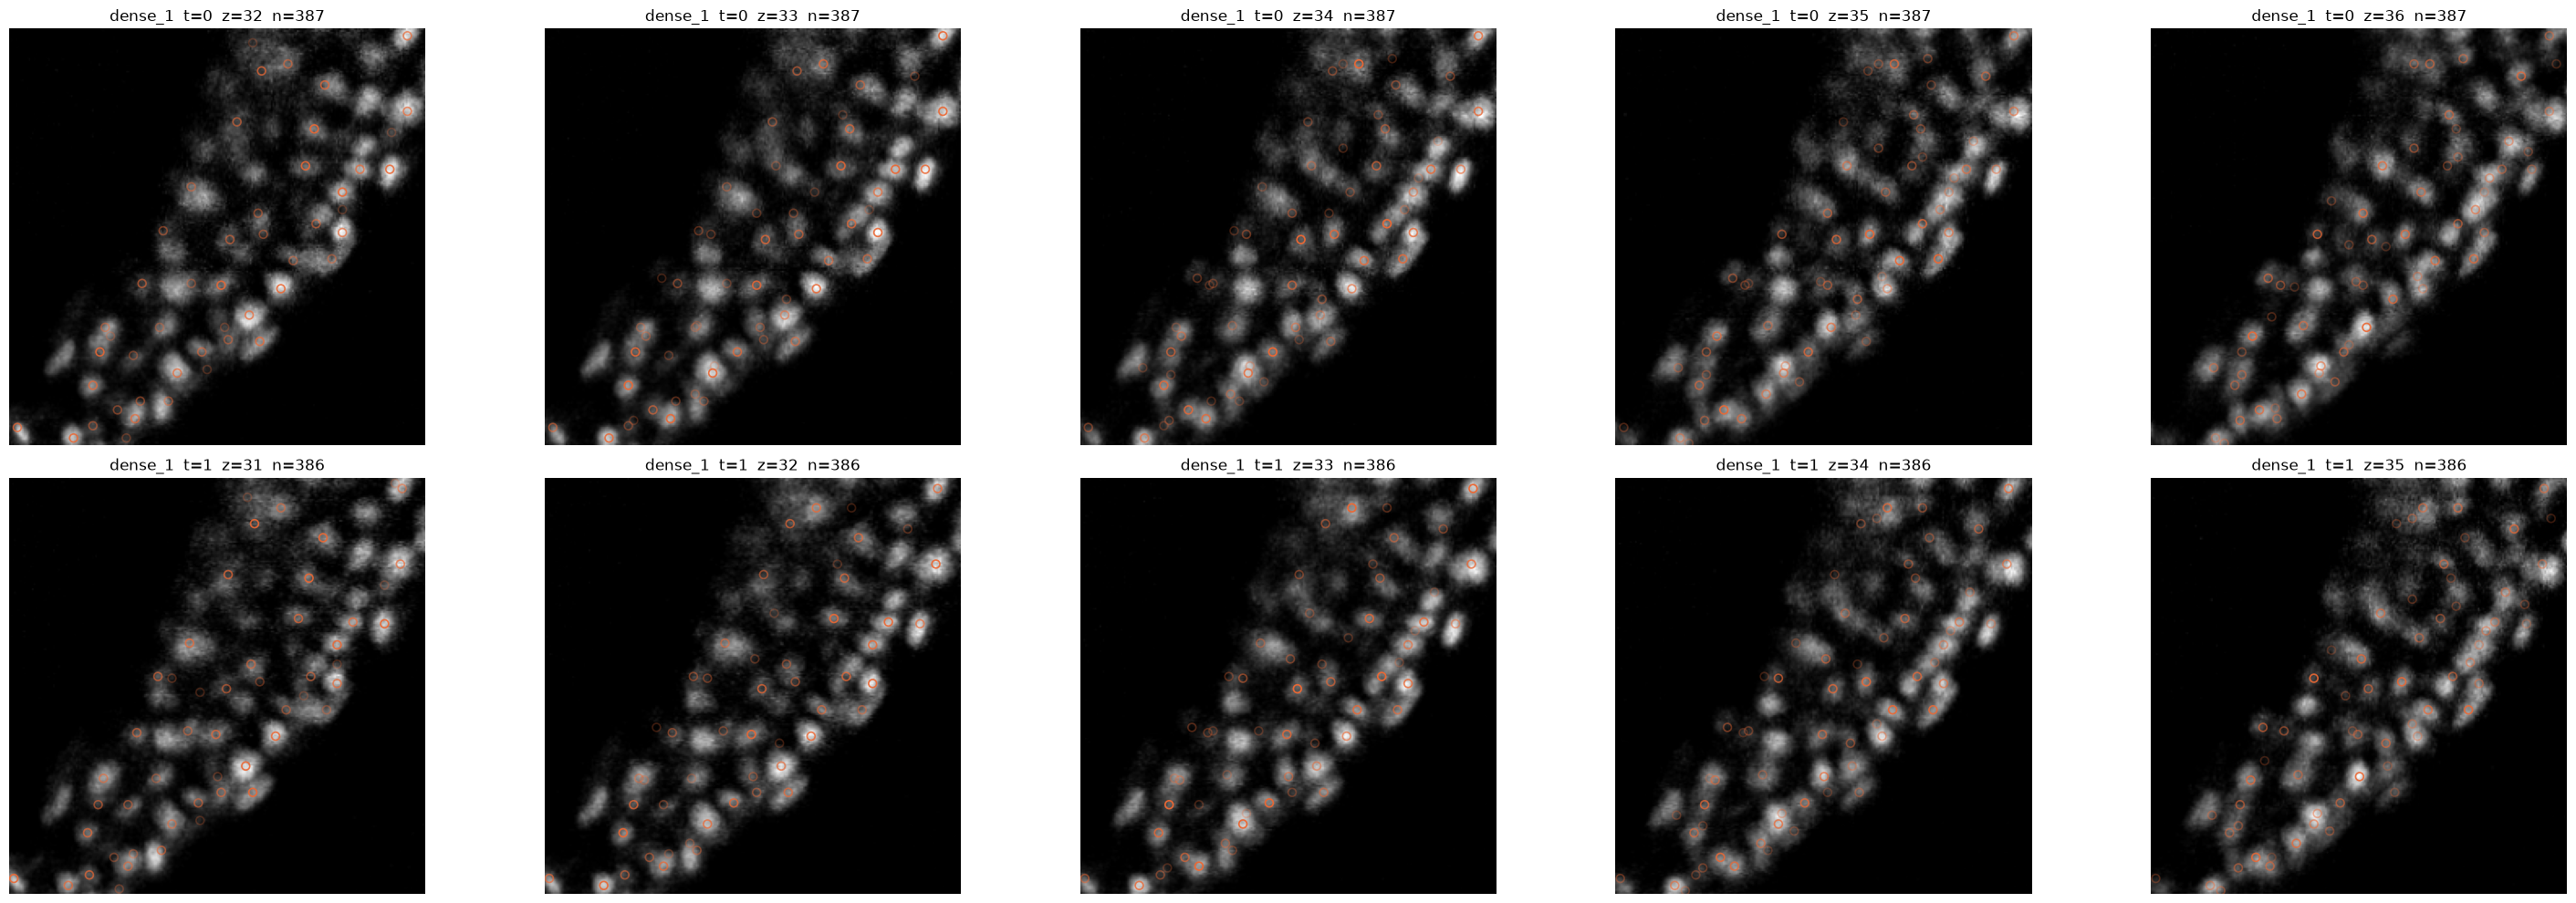

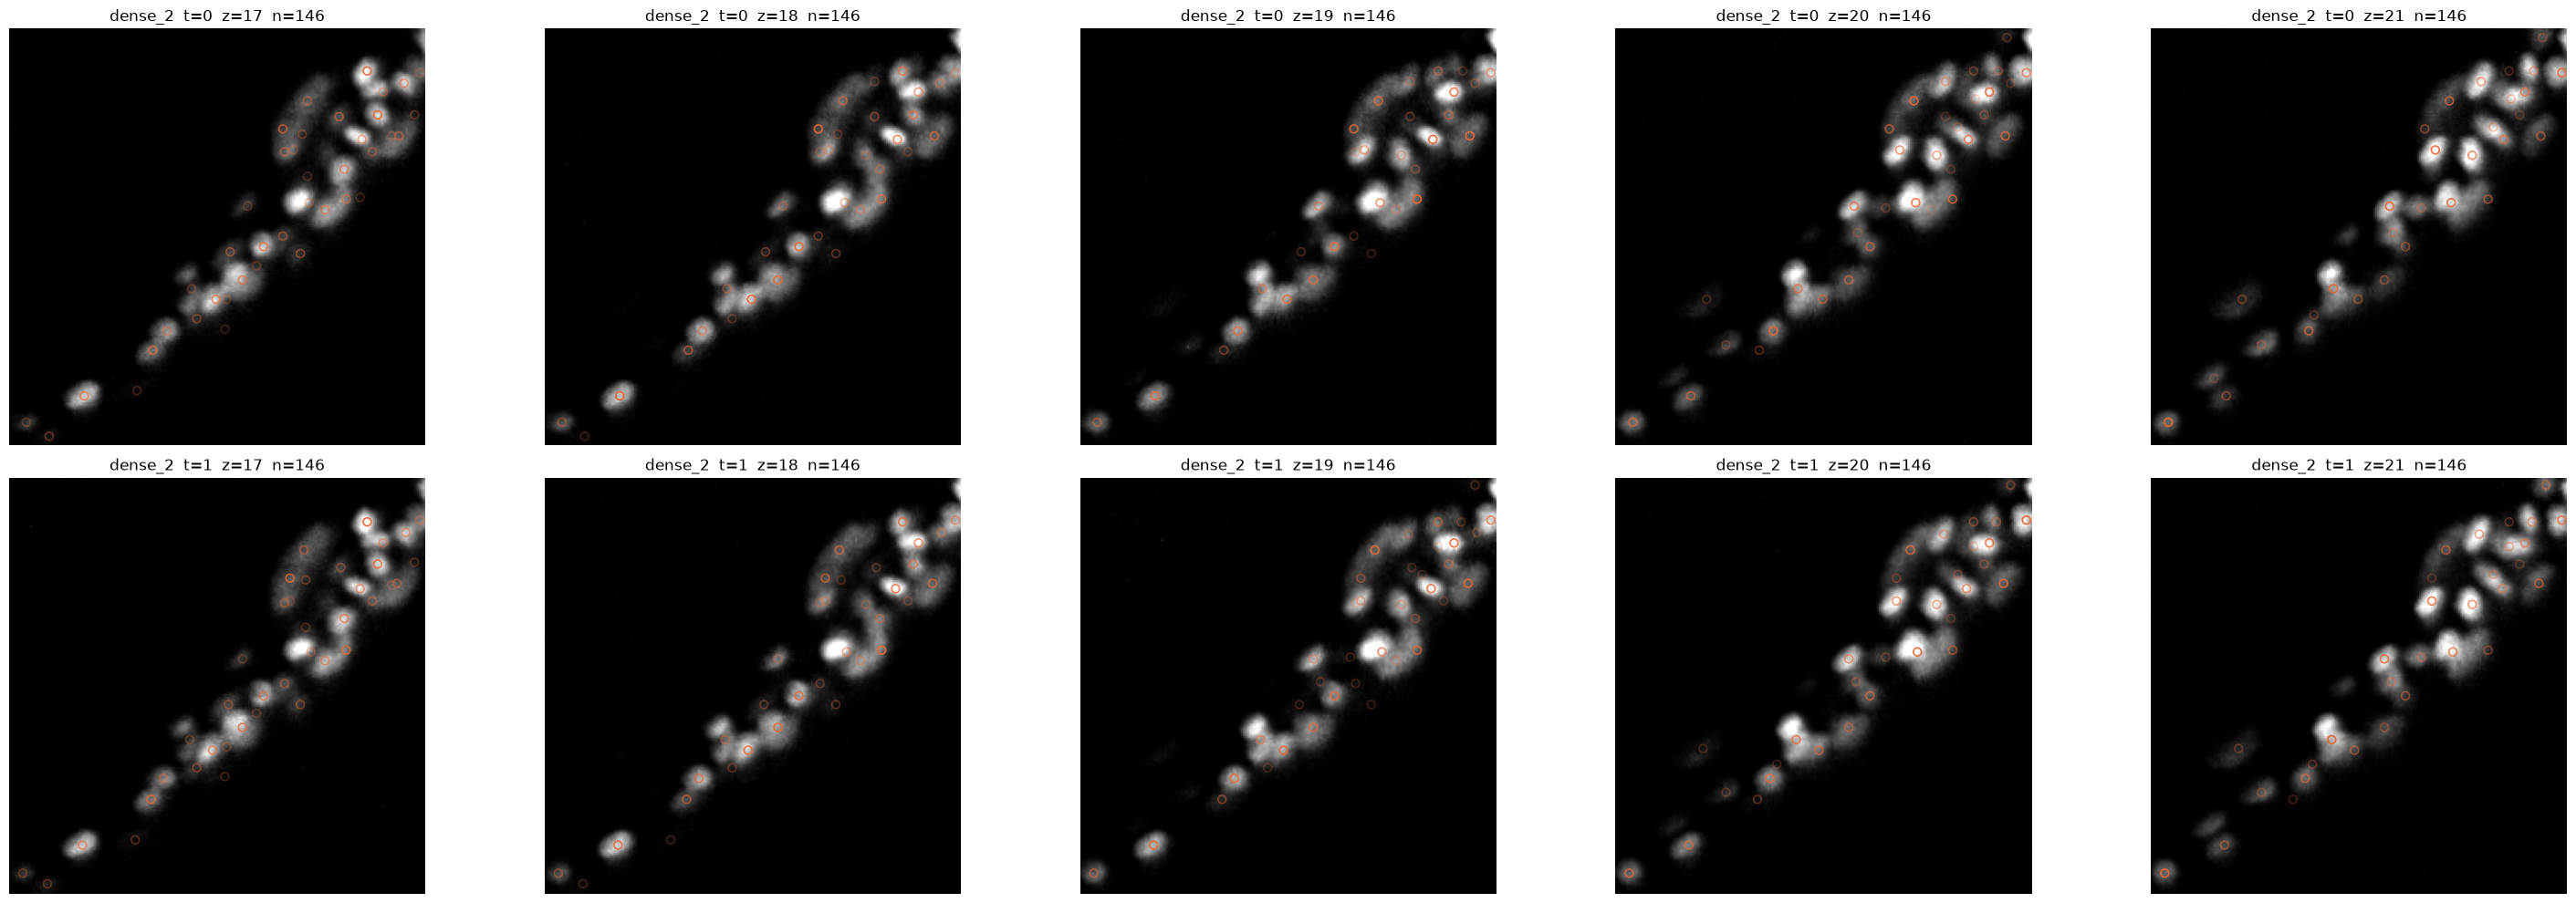

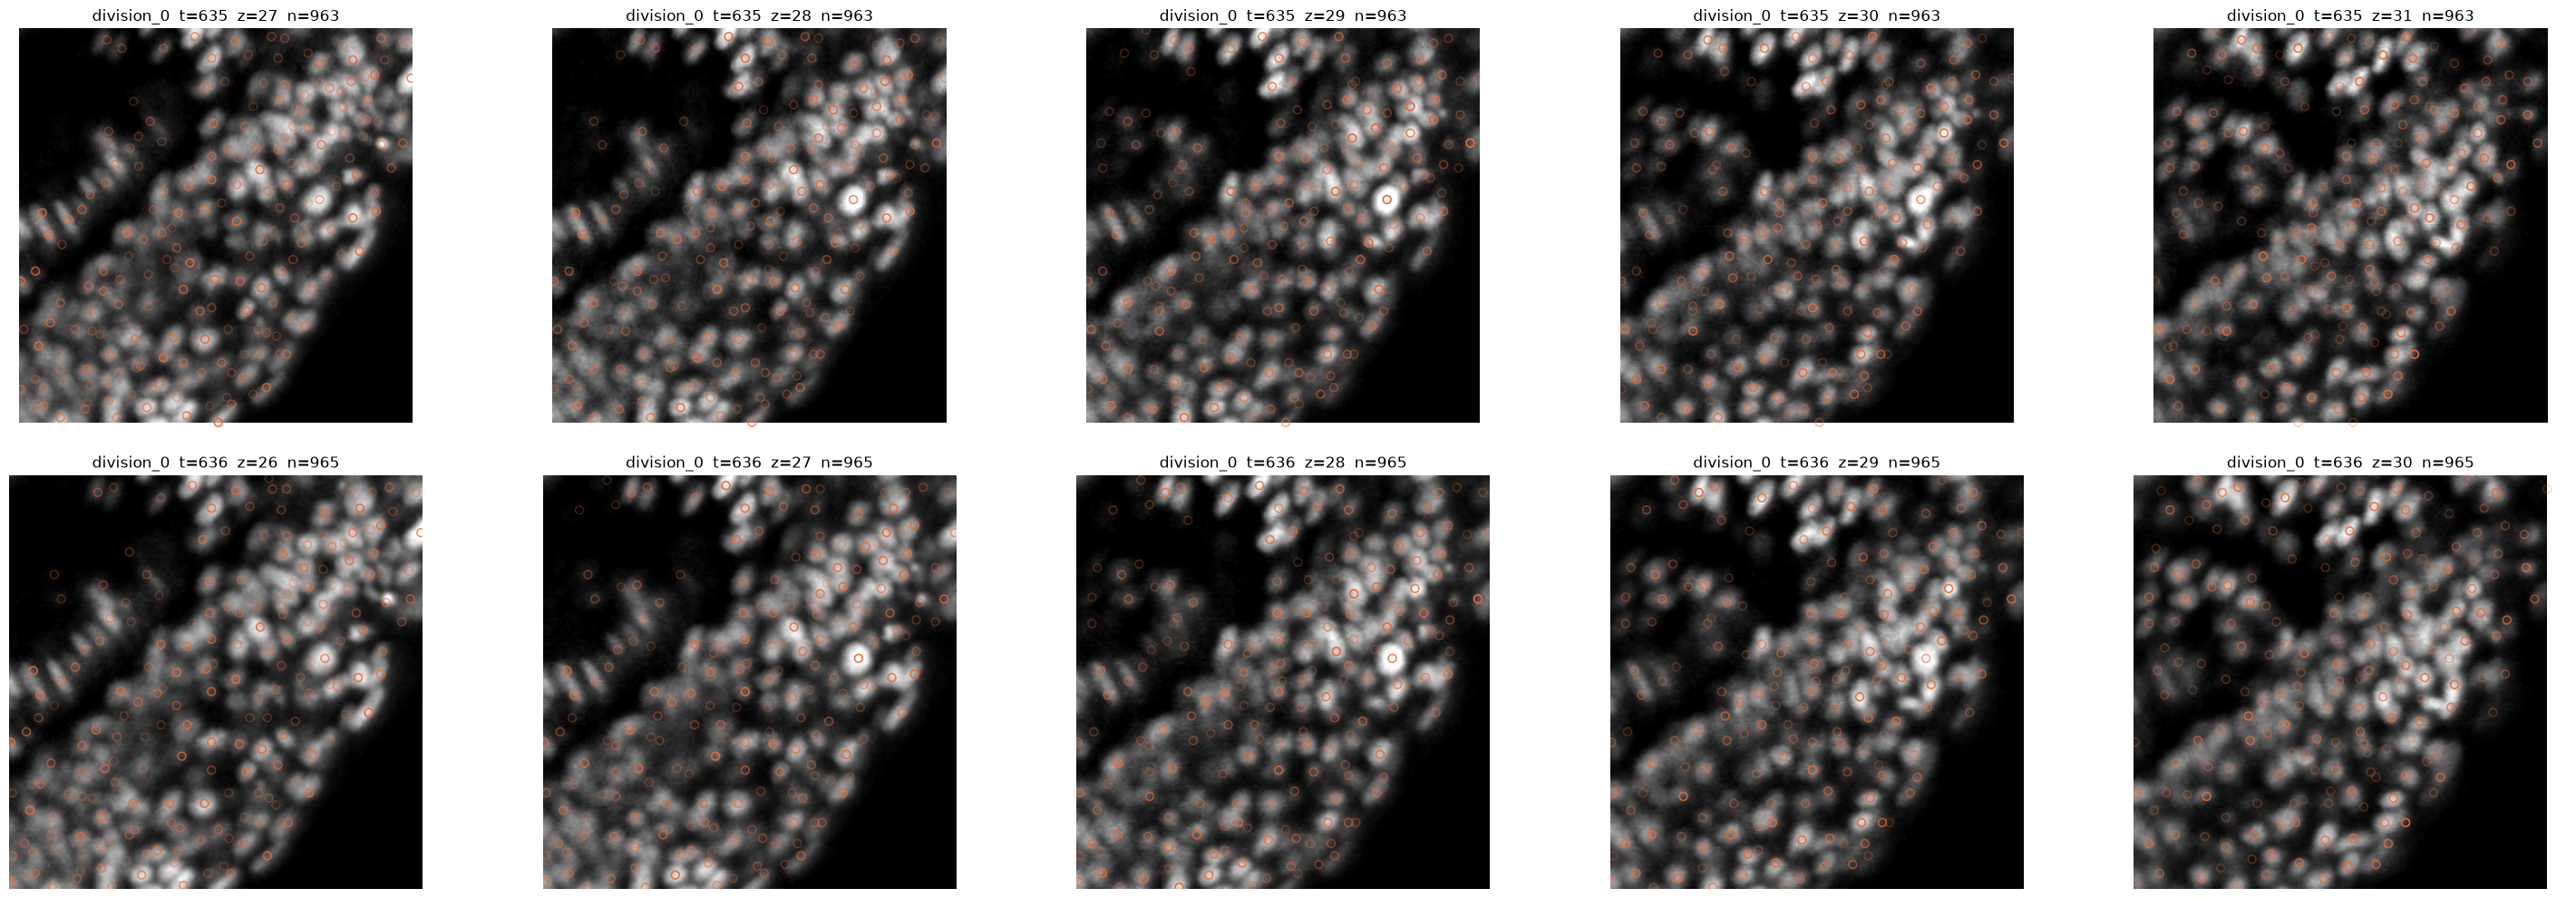

In [16]:

if len(CROP_SPECS) == 1:
    axes = axes[None, :]

for row, spec in enumerate(CROP_SPECS):

    fig, axes = plt.subplots(WINDOW_SIZE, 5, figsize=(30, 10))

    out = built[spec["name"]]
    nodes = out["nodes"]
    for w in range(WINDOW_SIZE):
        
        frame_nodes = nodes[nodes[:, 0] == w]
        z_plane = float(np.median(frame_nodes[:, 1])) if len(frame_nodes) else CROP_SHAPE[0] / 2
        z_planes = [z_plane - 2, z_plane - 1, z_plane, z_plane + 1, z_plane + 2]
        for z, z_plane in enumerate(z_planes):
            ax = axes[w, z]
            ax.imshow(out["volumes"][w, int(round(z_plane))], cmap="gray", vmax=np.quantile(out["volumes"], 0.999))
            scatter_by_depth(ax, frame_nodes[:, 1:4], z_plane, "#eb6834", tol=5, facecolor="none", s=40, linewidths=1.2)
            ax.set_title(f"{spec['name']}  t={spec['t0'] + w}  z={z_plane:.0f}  n={len(frame_nodes)}")
            ax.axis(False)
    plt.tight_layout()
    plt.show()


### Division crop close-up

The one crop centred on an actual division event: parent cell in frame 0,
both daughters in frame 1, connected by the edges built above.


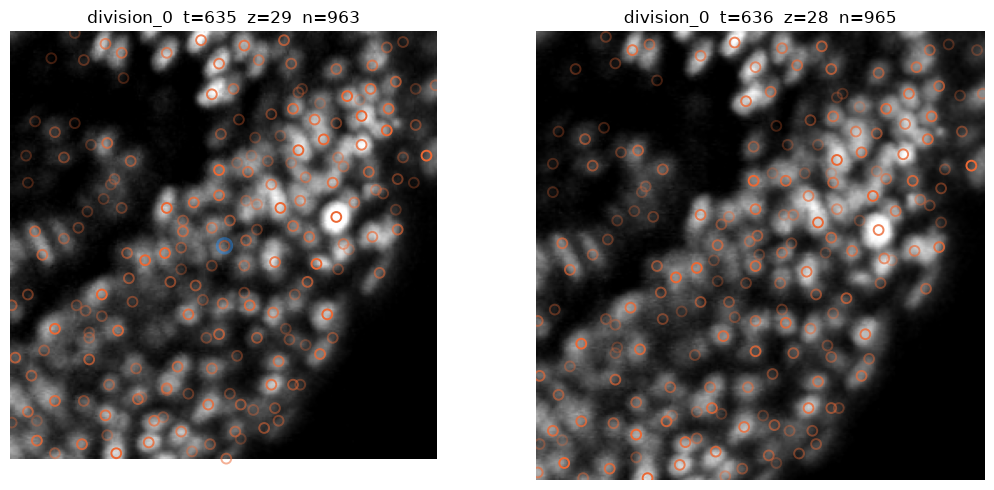

5 dividing node(s) in this crop, 945 edges total


In [14]:
div = built["division_0"]
nodes, edges = div["nodes"], div["edges"]
parent_rows = np.array([r for r in np.unique(edges[:, 0]) if (edges[:, 0] == r).sum() == 2])

fig, axes = plt.subplots(1, 2, figsize=(11, 5))
for w, ax in enumerate(axes):
    frame_nodes = nodes[nodes[:, 0] == w]
    z_plane = float(np.median(frame_nodes[:, 1])) if len(frame_nodes) else CROP_SHAPE[0] / 2
    ax.imshow(div["volumes"][w, int(round(z_plane))], cmap="gray", vmax=np.quantile(div["volumes"], 0.999))
    scatter_by_depth(ax, frame_nodes[:, 1:4], z_plane, "#eb6834", tol=5, facecolor="none", s=50, linewidths=1.4)
    if w == 0 and len(parent_rows):
        scatter_by_depth(ax, nodes[parent_rows][:, 1:4], z_plane, "dodgerblue", tol=5, facecolor="none",
                          s=110, linewidths=2.0)
    ax.set_title(f"division_0  t={div_t0 + w}  z={z_plane:.0f}  n={len(frame_nodes)}")
    ax.axis(False)
plt.tight_layout()
plt.show()

print(f"{len(parent_rows)} dividing node(s) in this crop, {div['edges'].shape[0]} edges total")


## Notes

- Only 4 crops here, purely for a first visual check — scale this notebook up
  (more `N_DENSE_CROPS`, denser grid `step_um`, more embryos/timepoints once
  `scripts/download_zebrahub.py` has fetched them) once the format looks
  right, and mirror `SyntheticData.ipynb`'s `metadata.json` idea for whatever
  the fuller run produces.
- `edges`/`divisions` only capture what happens strictly inside the crop's
  2-frame, 104³ µm window — a track leaving the crop or a division whose
  parent frame falls outside it will look like a track just ending, same as
  at the real data's own crop boundaries.
- `input/zebrahub_crops/` is not the synthetic generator's `input/synthetic/`
  path on purpose, so nothing here is picked up as synthetic data by mistake;
  wire it in explicitly (e.g. as its own `MixedDataset` component) if it goes
  into training.
